## 时间序列分析 第二次作业

### Problem 1. 中国宏观经济数据分析

(a) 请你针对中国国内生产总值系列数据完成以下分析：
  * 通过名义 GDP 累计值（NGDPA）计算名义 GDP（NGDP）并验证结果
  * 通过名义 GDP 与实际 GDP 同比增长率（RGDPYoY）计算 2020 年不变价格的实际 GDP（RGDP）并验证结果
  * 通过实际 GDP（RGDP）计算实际 GDP 累计同比增长率（RGDPYoYA）并验证结果
  * 请针对上述结果简要分析同比增长率与累计同比增长率的差异及原因

(b) 请你针对 2020 年不变价格的实际 GDP（RGDP）数据完成以下分析：
  * 请你分别采用 X-12-ARIMA，SEATS，STL，STAMP 四种季节调整方法对实际 GDP（RGDP）进行季节调整，并简要分析不同季节调整方法的差异
  * 请你通过季节调整后的实际 GDP 序列（基于 X-12-ARIMA 方法的调整后序列），计算并展示实际 GDP 环比增长率与对数环比增长率
  * 请你比较计算得到的实际 GDP 对数环比增长率与国家统计局 2012 年之后公布的官方序列，并简要分析环比增长率的优势
  * 请根据你所得到的实际同比增长率与实际环比增长率的走势，简要分析中国经济发展主要阶段以及相关的重要节点
  
(c) 请你针对 2020 年不变价格的实际 GDP（RGDP）数据完成以下分析：
  * 请你分别采用 Hodrick-Prescott 滤波，Baxter-King 滤波，Christiano-Fitzgerald 滤波三种方式对实际 GDP (RGDP) 进行趋势分解
  * 若将趋势成分解释为潜在产出，则周期成分可视为产出缺口的近似度量，即实际产出相对于潜在产出的偏离，请基于上述概念计算产出缺口
  * 请你绘制通货膨胀率 (CPIMoM) 与产出缺口的散点图，并尝试分析通货膨胀与产出缺口之间可能存在的关系
  
### Problem 2. 美国宏观经济数据分析

(a) 请你针对美国 FRED-MD 数据完成以下分析
  * 针对原始论文中推荐的 TCODE 对原始数据进行平稳化处理
  * 针对每一种处理方法简要分析其统计含义以及其适用环境

(b) 请你针对平稳化序列进行后续分析
  * 基于 IQR 准则剔除极端值，并展示剔除极端值前后的平稳序列
  * 请简要分析美国宏观经济数据中极端异常值出现的时期，以及在实际分析中如何权衡异常值的剔除与保留
  * 剔除极端异常值后，请对所有序列进行 Z-Score 标准变换，并集中展示标准化的序列

(c) 请你针对清理后的美国月度宏观经济数据进行补充分析（可选）
  * 请针对处理后的日度序列采用动态因子模型提取出原始序列的共同因子，并展示该共同因子与美国季度 GDP 环比增速
  * 根据结果分析月度宏观经济数据与季度 GDP 走势是否具有关联性？以及能否利用高频的月度数据提升季度 GDP 的预测？

### 中国宏观经济数据分析

In [1]:
import os
import re
import tempfile
import warnings
from io import StringIO

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdate

import statsmodels.api as sm
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.x13 import run_spec
from statsmodels.tsa.x13 import x13_arima_analysis
from statsmodels.tsa.filters.hp_filter import hpfilter
from statsmodels.tsa.filters.bk_filter import bkfilter
from statsmodels.tsa.filters.cf_filter import cffilter
warnings.filterwarnings("ignore")

plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["xtick.direction"] = "in"

formatter = mdate.DateFormatter("%Y")   # %Y-%m -> 2023-01; %b %Y -> Jan 2023
marjorlocator = mdate.YearLocator(4)    # mdate.MonthLocator(bymonth=[1,7])

path = os.getcwd()
data = pd.read_excel(os.path.join(path, "DATACN.xlsx"), sheet_name="QD")
data["Date"] = pd.to_datetime(data["Date"]) + pd.offsets.MonthEnd(0)
data = data.set_index("Date")

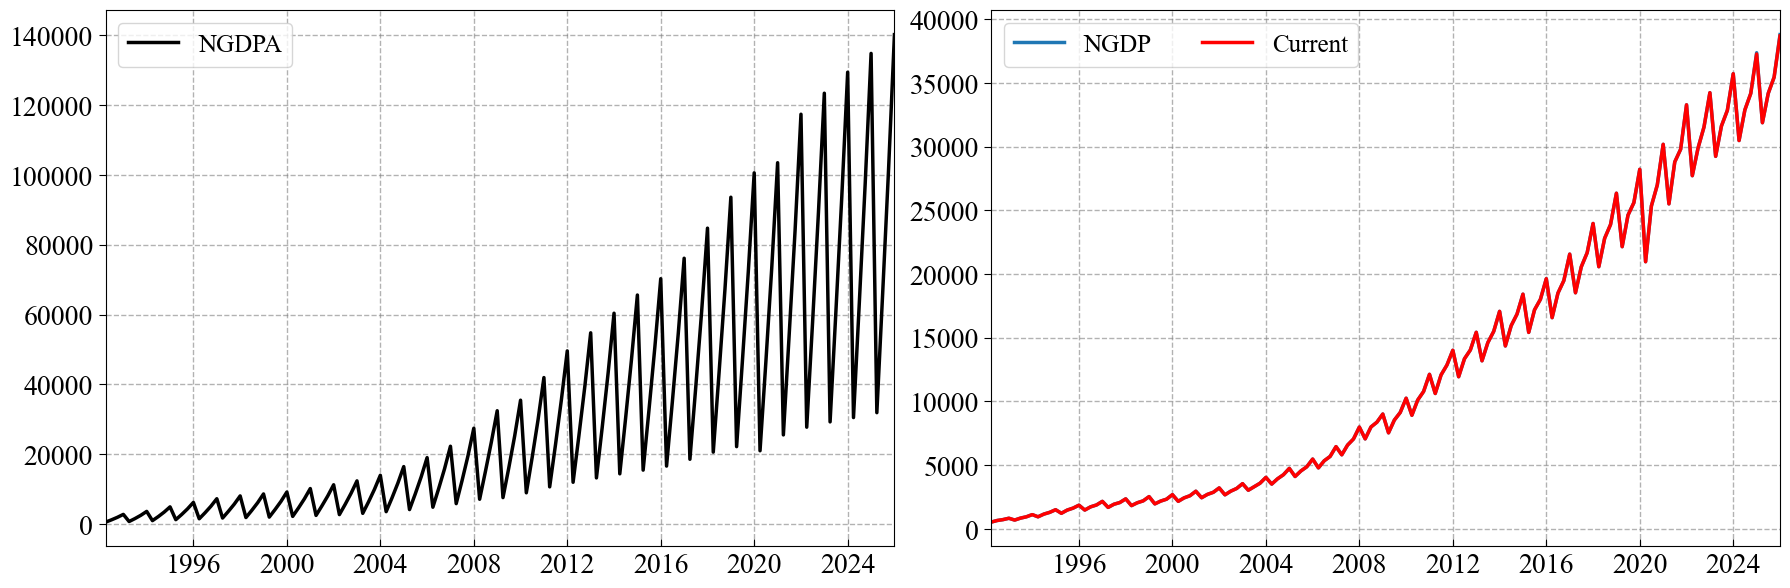

In [2]:
# 累计值与当期值转换
def Accumulated2Current(series):
    # 按年份分组：每年内做差分，Q1 自动保留原值
    current = series.groupby(series.index.year).diff()
    current = current.where(~current.isna(), series)
    return current

series = data["NGDPA"].copy()
current = Accumulated2Current(series)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))
ax[0].plot(series.index, series, color="#000000", alpha=1, linewidth=2.5, label="NGDPA")
ax[0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0].set_xlim(series.index[0], series.index[-1])
ax[0].legend(fontsize=18, ncol=2)
ax[1].plot(series.index, data["NGDP"], color="#1F77B4", alpha=1, linewidth=2.5, label="NGDP")
ax[1].plot(current.index, current, color="#FF0000", alpha=1, linewidth=2.5, label="Current")
ax[1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1].set_xlim(series.index[0], series.index[-1])
ax[1].legend(fontsize=18, ncol=2)
plt.tight_layout()
fig.savefig("Accumulated2Current.pdf", format="pdf", bbox_inches="tight")
plt.show()

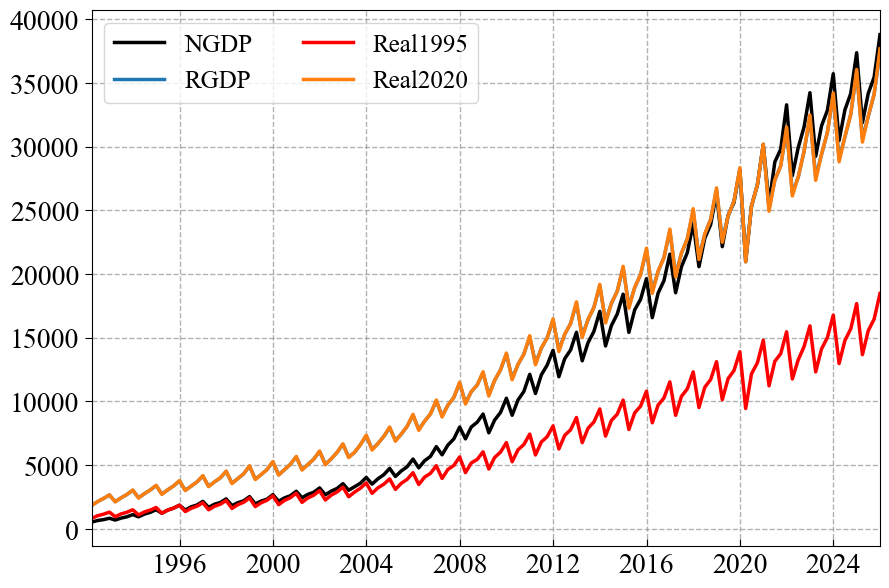

In [3]:
# 名义值与实际值转换
def Norminal2Real(nominal, yoygrowth, base):
    real = pd.Series(index=nominal.index, dtype="float64")

    # 1. 先把基期年份内的值设为名义值
    mask = nominal.index.year == base
    real.loc[mask] = nominal.loc[mask]
    idx = nominal.index
    # 2. 向前递推：基期年之后
    for i in range(len(idx)):
        ts = idx[i]
        if ts.year <= base:
            continue
        previ = i - 4
        if previ < 0:
            continue
        growth = yoygrowth.iloc[i]
        if pd.notna(real.iloc[previ]) and pd.notna(growth):
            real.iloc[i] = real.iloc[previ] * (1 + growth / 100.0)

    # 3. 向后倒推：基期年之前
    for i in range(len(idx) - 1, -1, -1):
        ts = idx[i]
        if ts.year >= base:
            continue
        nexti = i + 4
        if nexti >= len(idx):
            continue
        growthnext = yoygrowth.iloc[nexti]
        if pd.notna(real.iloc[nexti]) and pd.notna(growthnext):
            denom = 1 + growthnext/ 100.0
            if denom == 0:
                real.iloc[i] = np.nan
            else:
                real.iloc[i] = real.iloc[nexti] / denom
    return real

nominal = data["NGDP"].copy()
yoygrowth = data["RGDPYoY"].copy()
real = Norminal2Real(nominal, yoygrowth, 1995) # 可尝试不同年份观察基期变化

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(9, 6))
ax.plot(nominal.index, nominal, color="#000000", alpha=1, linewidth=2.5, label="NGDP")
ax.plot(nominal.index, data["RGDP"], color="#1F77B4", alpha=1, linewidth=2.5, label="RGDP")
ax.plot(real.index, real, color="#FF0000", alpha=1, linewidth=2.5, label="Real1995")
real = Norminal2Real(nominal, yoygrowth, 2020) # 可尝试不同年份观察基期变化
ax.plot(real.index, real, color="#FF7F0E", alpha=1, linewidth=2.5, label="Real2020")
ax.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax.set_xlim(series.index[0], series.index[-1])
ax.legend(fontsize=18, ncol=2)
plt.tight_layout()
fig.savefig("Norminal2Real.pdf", format="pdf", bbox_inches="tight")
plt.show()

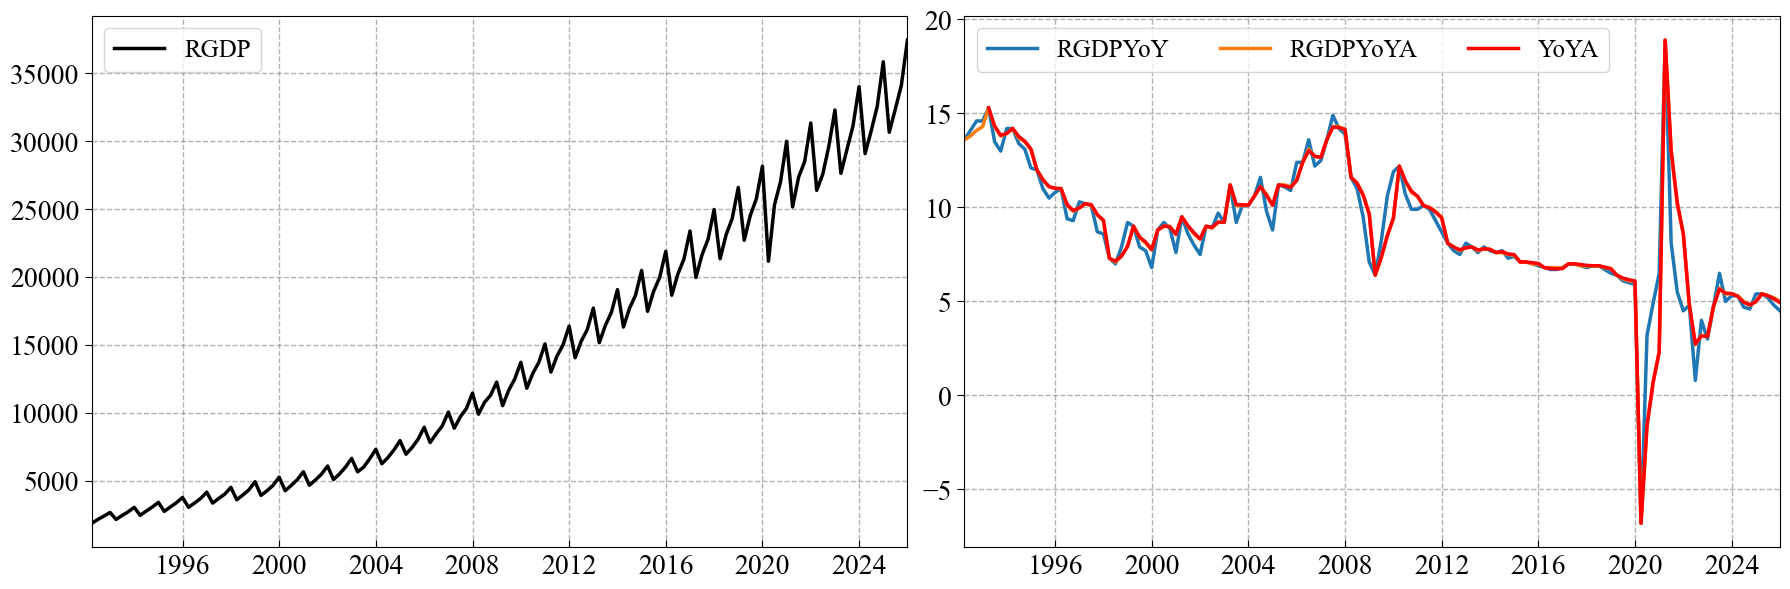

In [4]:
# 当期值与累计同比增长率转换
def Current2AccumulatedYoY(series):
    # 1. 按年内累计
    accumulated = series.groupby(series.index.year).cumsum()
    # 2. 计算累计同比增长率
    yoya = (accumulated / accumulated.shift(4) - 1) * 100
    return yoya

series = data["RGDP"].copy()
yoya = Current2AccumulatedYoY(series)

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(18, 6))
ax[0].plot(series.index, series, color="#000000", alpha=1, linewidth=2.5, label="RGDP")
ax[0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0].set_xlim(series.index[0], series.index[-1])
ax[0].legend(fontsize=18, ncol=3)

ax[1].plot(series.index, data["RGDPYoY"], color="#1F77B4", alpha=1, linewidth=2.5, label="RGDPYoY")
ax[1].plot(series.index, data["RGDPYoYA"], color="#FF7F0E", alpha=1, linewidth=2.5, label="RGDPYoYA")
ax[1].plot(yoya.index, yoya, color="#FF0000", alpha=1, linewidth=2.5, label="YoYA")
ax[1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1].set_xlim(series.index[0], series.index[-1])
ax[1].legend(fontsize=18, ncol=3)
plt.tight_layout()
fig.savefig("Current2AccumulatedYoY.pdf", format="pdf", bbox_inches="tight")
plt.show()

✓ STAMP 处理完成
✓ STL 处理完成
✓ X-13-ARIMA 分解完成
✓ SEATS 分解完成


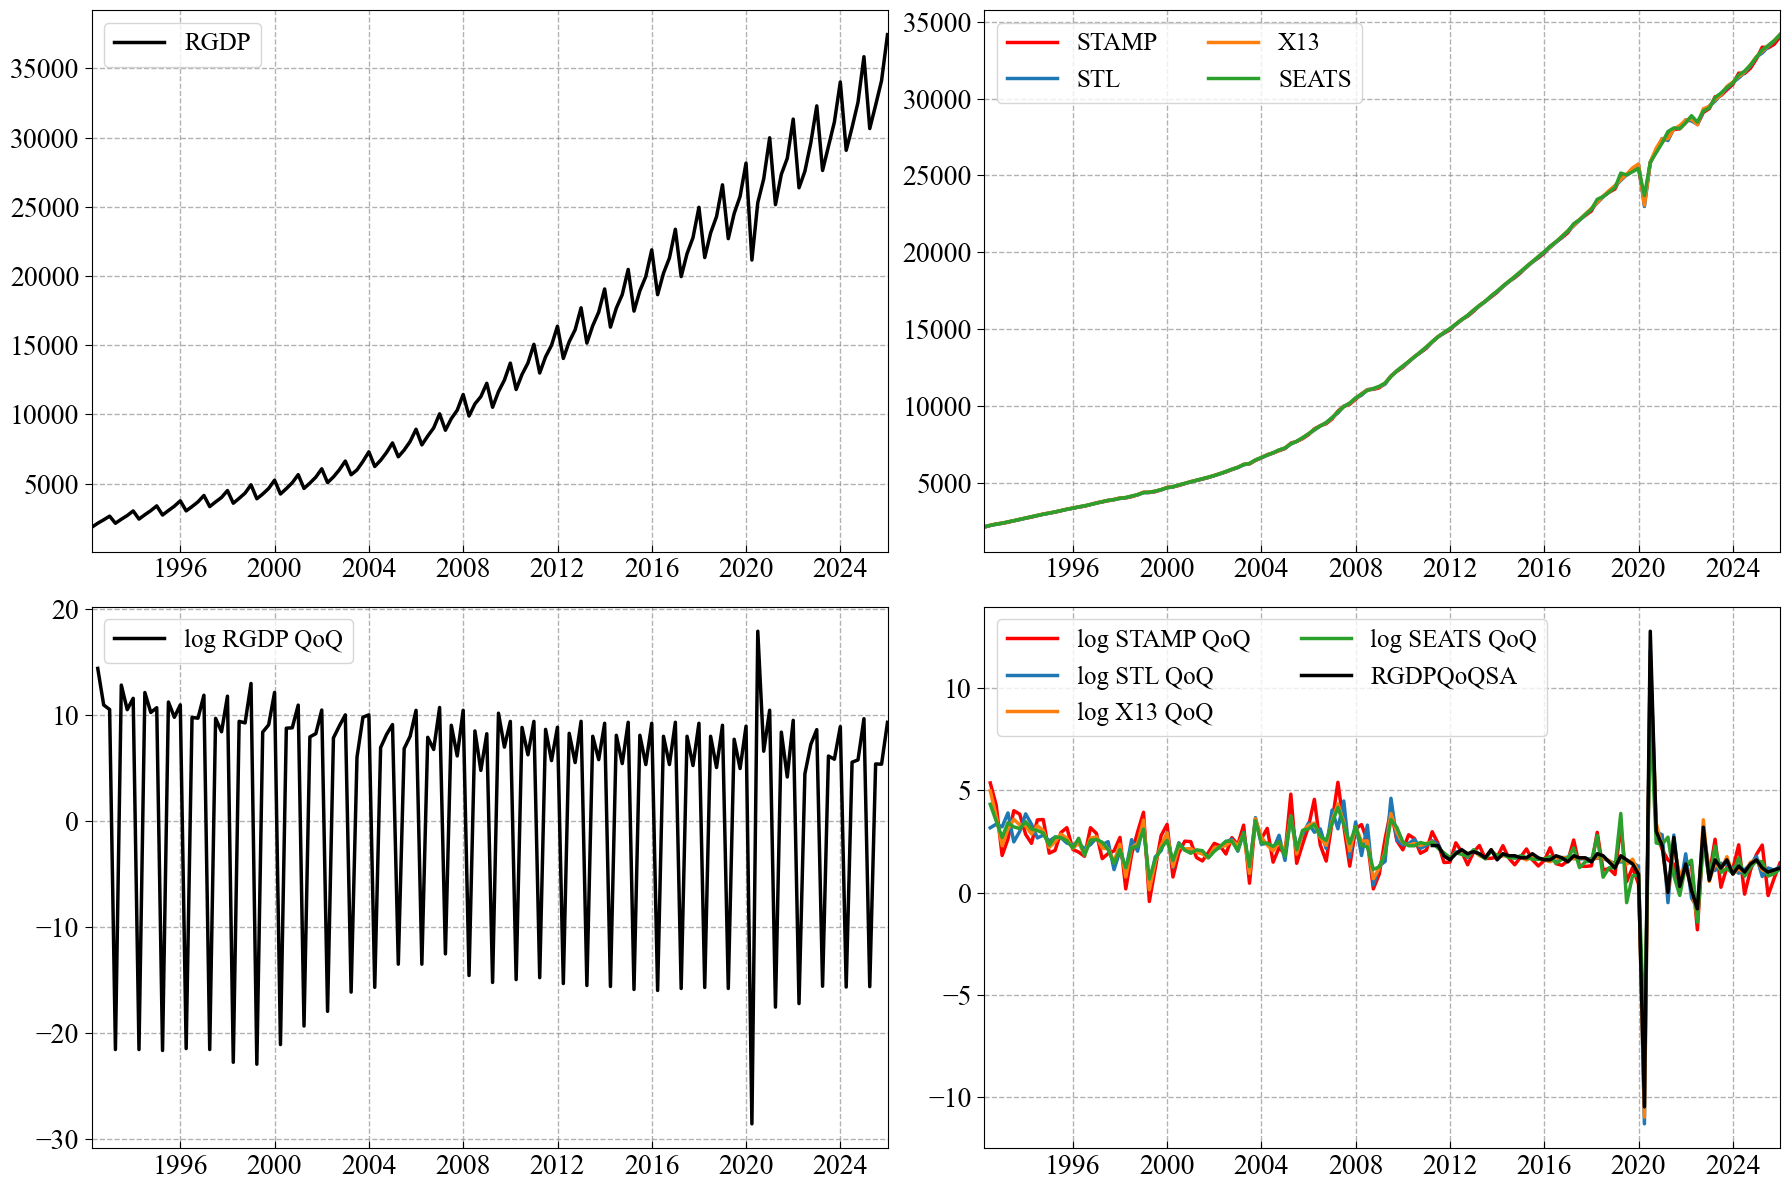

In [5]:
# 季节调整方法
class ChinaGDPAnalyzer:
    def __init__(self, series, x13_path=None):
        # 1. 数据加载与预处理
        self.series = series
        self.x13_path = x13_path
        self.results = pd.DataFrame(index=self.series.index)
        self.results["Original"] = self.series

    def run_stamp(self):
        """STAMP (基于状态空间模型的结构化时间序列分解)"""
        # 对数变换处理乘法效应
        log_data = np.log(self.series)
        model = sm.tsa.UnobservedComponents(log_data, level="local level", seasonal=4)
        res = model.fit(disp=False)
        # 季节调整：Original / Exp(Seasonal)
        sa_log = log_data - res.seasonal.smoothed
        self.results['STAMP_SA'] = np.exp(sa_log)
        print("✓ STAMP 处理完成")

    def run_stl(self):
        """STL (基于LOESS的鲁棒分解)"""
        log_data = np.log(self.series)
        # period=4 对应季度数据，robust=True 处理异常值
        stl = STL(log_data, period=4, robust=True)
        res = stl.fit()
        sa_log = log_data - res.seasonal
        self.results["STL_SA"] = np.exp(sa_log)
        print("✓ STL 处理完成")

    def run_x12(self):
        """X-13ARIMA-SEATS 分解"""
        if not self.x13_path or not os.path.exists(self.x13_path):
            print("! 警告: 未找到 X13 路径，跳过 X-13ARIMA-SEATS")
            return
        # X-13 自动处理对数变换和异常值
        res = x13_arima_analysis(self.series, x12path=self.x13_path, log=True)
        self.results["X13_SA"] = res.seasadj
        print("✓ X-13-ARIMA 分解完成")

    def run_seats(self):
        """X-13ARIMA-SEATS 分解"""
        if not self.x13_path or not os.path.exists(self.x13_path):
            print("! 警告: 未找到 X13 路径，跳过 X-13ARIMA-SEATS")
            return
        
        start_date = f"{self.series.index[0].year}.{self.series.index[0].quarter}"

        with tempfile.TemporaryDirectory() as tmpdir:
            data_file = os.path.join(tmpdir, "seats.dat")
            with open(data_file, "w", encoding="utf-8", newline="\n") as file:
                for value in self.series.tolist():
                    file.write(f"{value}\n")

            spec = """
                series {{
                    title = "SEATS Seasonal Adjustment"
                    start = {}
                    period = 4
                    file = "{}"
                }}
                transform {{
                    function = auto
                }}
                automdl {{
                }}
                seats {{
                    save = (s11 s10 s12 s13)
                }}
            """.format(start_date, data_file.replace("\\\\", "/"))

            spec_file = os.path.join(tmpdir, "seats.spc")
            with open(spec_file, "w", encoding="utf-8", newline="\n") as file:
                file.write(spec)
                if not spec.endswith("\n"):
                    file.write("\n")

            spec_stem = os.path.splitext(spec_file)[0]
            out_stem = os.path.join(tmpdir, "seatsout")

            p = run_spec(os.path.join(self.x13_path, "x13as_ascii.exe"), spec_stem, out_stem)
            p.wait()

            s11_file = out_stem + ".s11"
            with open(s11_file, "r", encoding="utf-8", errors="ignore") as file:
                result_txt = file.read()
            seasadj = pd.read_csv(StringIO(result_txt), sep=r"\s+", skiprows=2, header=None, engine="python")
            self.results["SEATS_SA"] = seasadj.iloc[:, 1].tolist()
        print("✓ SEATS 分解完成")

series = data["RGDP"].copy()
analyzer = ChinaGDPAnalyzer(series, x13_path=path)
analyzer.run_stamp()
analyzer.run_stl()
analyzer.run_x12()   # 经典的 X-11
analyzer.run_seats()
seasonadjusted = analyzer.results

# 名义值与实际值转换
fig, ax = plt.subplots(nrows=2, ncols=2, figsize=(18, 12))
ax[0, 0].plot(series.index, series, color="#000000", alpha=1, linewidth=2.5, label="RGDP")
ax[0, 0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0, 0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0, 0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0, 0].set_xlim(series.index[0], series.index[-1])
ax[0, 0].legend(fontsize=18, ncol=3)

ax[0, 1].plot(seasonadjusted.index, seasonadjusted["STAMP_SA"], color="#FF0000", alpha=1, linewidth=2.5, label="STAMP")
ax[0, 1].plot(seasonadjusted.index, seasonadjusted["STL_SA"], color="#1F77B4", alpha=1, linewidth=2.5, label="STL")
ax[0, 1].plot(seasonadjusted.index, seasonadjusted["X13_SA"], color="#FF7F0E", alpha=1, linewidth=2.5, label="X13")
ax[0, 1].plot(seasonadjusted.index, seasonadjusted["SEATS_SA"], color="#2CA02C", alpha=1, linewidth=2.5, label="SEATS")
ax[0, 1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0, 1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0, 1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0, 1].set_xlim(series.index[0], series.index[-1])
ax[0, 1].legend(fontsize=18, ncol=2)

ax[1, 0].plot(series.index, np.log(series).diff(1) * 100, color="#000000", alpha=1, linewidth=2.5, label="log RGDP QoQ")
ax[1, 0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1, 0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1, 0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1, 0].set_xlim(series.index[0], series.index[-1])
ax[1, 0].legend(fontsize=18, ncol=3)

ax[1, 1].plot(seasonadjusted.index, np.log(seasonadjusted["STAMP_SA"]).diff(1) * 100, color="#FF0000", alpha=1, linewidth=2.5, label="log STAMP QoQ")
ax[1, 1].plot(seasonadjusted.index, np.log(seasonadjusted["STL_SA"]).diff(1) * 100, color="#1F77B4", alpha=1, linewidth=2.5, label="log STL QoQ")
ax[1, 1].plot(seasonadjusted.index, np.log(seasonadjusted["X13_SA"]).diff(1) * 100, color="#FF7F0E", alpha=1, linewidth=2.5, label="log X13 QoQ")
ax[1, 1].plot(seasonadjusted.index, np.log(seasonadjusted["SEATS_SA"]).diff(1) * 100, color="#2CA02C", alpha=1, linewidth=2.5, label="log SEATS QoQ")
ax[1, 1].plot(series.index, data["RGDPQoQSA"], color="#000000", alpha=1, linewidth=2.5, label="RGDPQoQSA")
ax[1, 1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1, 1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1, 1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1, 1].set_xlim(series.index[0], series.index[-1])
ax[1, 1].legend(fontsize=18, ncol=2)

plt.tight_layout()
fig.savefig("SeasonalAdjustment.pdf", format="pdf", bbox_inches="tight")
plt.show()

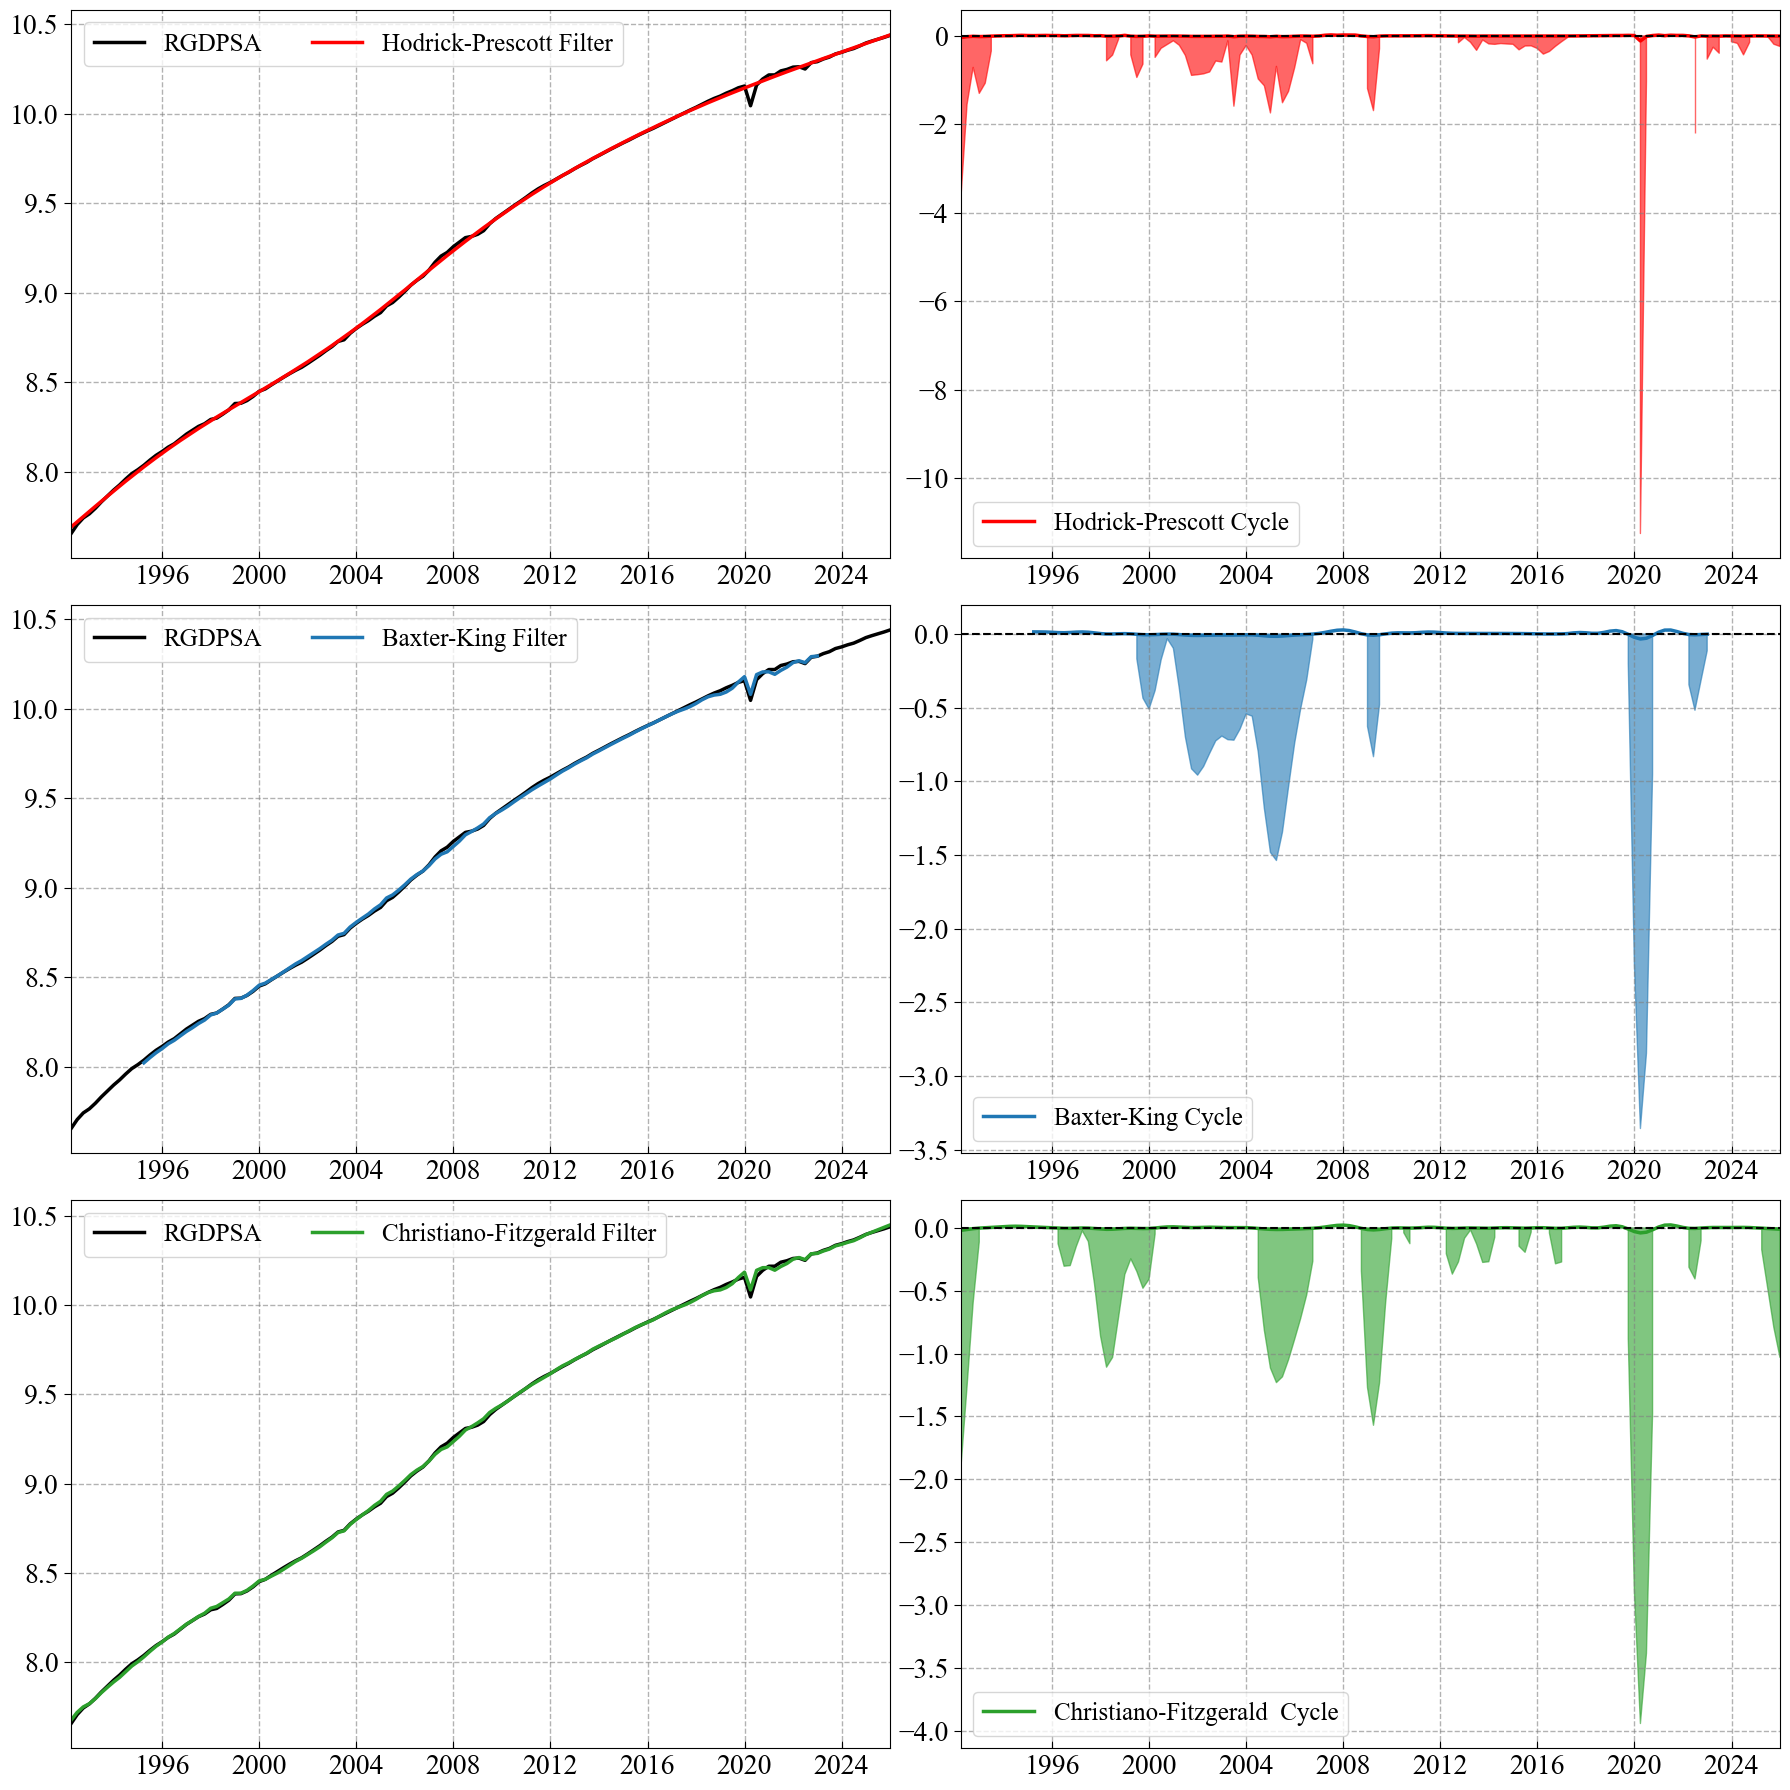

In [6]:
# 趋势周期分解
series = seasonadjusted["X13_SA"].copy()
logGDP = np.log(series)

# Hodrick-Prescott 滤波
hpcycle, hptrend = hpfilter(logGDP, lamb=1600)

# Baxter-King 滤波
bkcycle = bkfilter(logGDP, low=6, high=32, K=12)
bktrend = logGDP.iloc[12:-12] - bkcycle

# Christiano-Fitzgerald 滤波
cfcycle, _ = cffilter(logGDP, low=6, high=32, drift=True)
cftrend = logGDP - cfcycle

fig, ax = plt.subplots(nrows=3, ncols=2, figsize=(18, 18))

ax[0, 0].plot(series.index, np.log(series), color="#000000", alpha=1, linewidth=2.5, label="RGDPSA")
ax[0, 0].plot(hptrend.index, hptrend, color="#FF0000", alpha=1, linewidth=2.5, label="Hodrick-Prescott Filter")
ax[0, 0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0, 0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0, 0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0, 0].set_xlim(series.index[0], series.index[-1])
ax[0, 0].legend(fontsize=18, ncol=3)

ax[0, 1].plot(hpcycle.index, hpcycle, color="#FF0000", alpha=1, linewidth=2.5, label="Hodrick-Prescott Cycle")
ax[0, 1].axhline(0, color="black", linestyle="--", linewidth=1.5)
ax[0, 1].fill_between(hpcycle.index, 0, hpcycle * 100, where=(hpcycle < 0), color="#FF0000", alpha=0.6)
ax[0, 1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[0, 1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[0, 1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[0, 1].set_xlim(series.index[0], series.index[-1])
ax[0, 1].legend(fontsize=18, ncol=3)

ax[1, 0].plot(series.index, np.log(series), color="#000000", alpha=1, linewidth=2.5, label="RGDPSA")
ax[1, 0].plot(bktrend.index, bktrend, color="#1F77B4", alpha=1, linewidth=2.5, label="Baxter-King Filter")
ax[1, 0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1, 0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1, 0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1, 0].set_xlim(series.index[0], series.index[-1])
ax[1, 0].legend(fontsize=18, ncol=3)

ax[1, 1].plot(bkcycle.index, bkcycle, color="#1F77B4", alpha=1, linewidth=2.5, label="Baxter-King Cycle")
ax[1, 1].axhline(0, color="black", linestyle="--", linewidth=1.5)
ax[1, 1].fill_between(bkcycle.index, 0, bkcycle * 100, where=(bkcycle < 0), color="#1F77B4", alpha=0.6)
ax[1, 1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[1, 1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[1, 1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[1, 1].set_xlim(series.index[0], series.index[-1])
ax[1, 1].legend(fontsize=18, ncol=3)

ax[2, 0].plot(series.index, np.log(series), color="#000000", alpha=1, linewidth=2.5, label="RGDPSA")
ax[2, 0].plot(cftrend.index, cftrend, color="#2CA02C", alpha=1, linewidth=2.5, label="Christiano-Fitzgerald Filter")
ax[2, 0].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[2, 0].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[2, 0].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[2, 0].set_xlim(series.index[0], series.index[-1])
ax[2, 0].legend(fontsize=18, ncol=3)

ax[2, 1].plot(cfcycle.index, cfcycle, color="#2CA02C", alpha=1, linewidth=2.5, label="Christiano-Fitzgerald  Cycle")
ax[2, 1].axhline(0, color="black", linestyle="--", linewidth=1.5)
ax[2, 1].fill_between(cfcycle.index, 0, cfcycle * 100, where=(cfcycle < 0), color="#2CA02C", alpha=0.6)
ax[2, 1].grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax[2, 1].tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax[2, 1].tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax[2, 1].set_xlim(series.index[0], series.index[-1])
ax[2, 1].legend(fontsize=18, ncol=3)

plt.tight_layout()
fig.savefig("TrendCycleDecomposition.pdf", format="pdf", bbox_inches="tight")
plt.show()

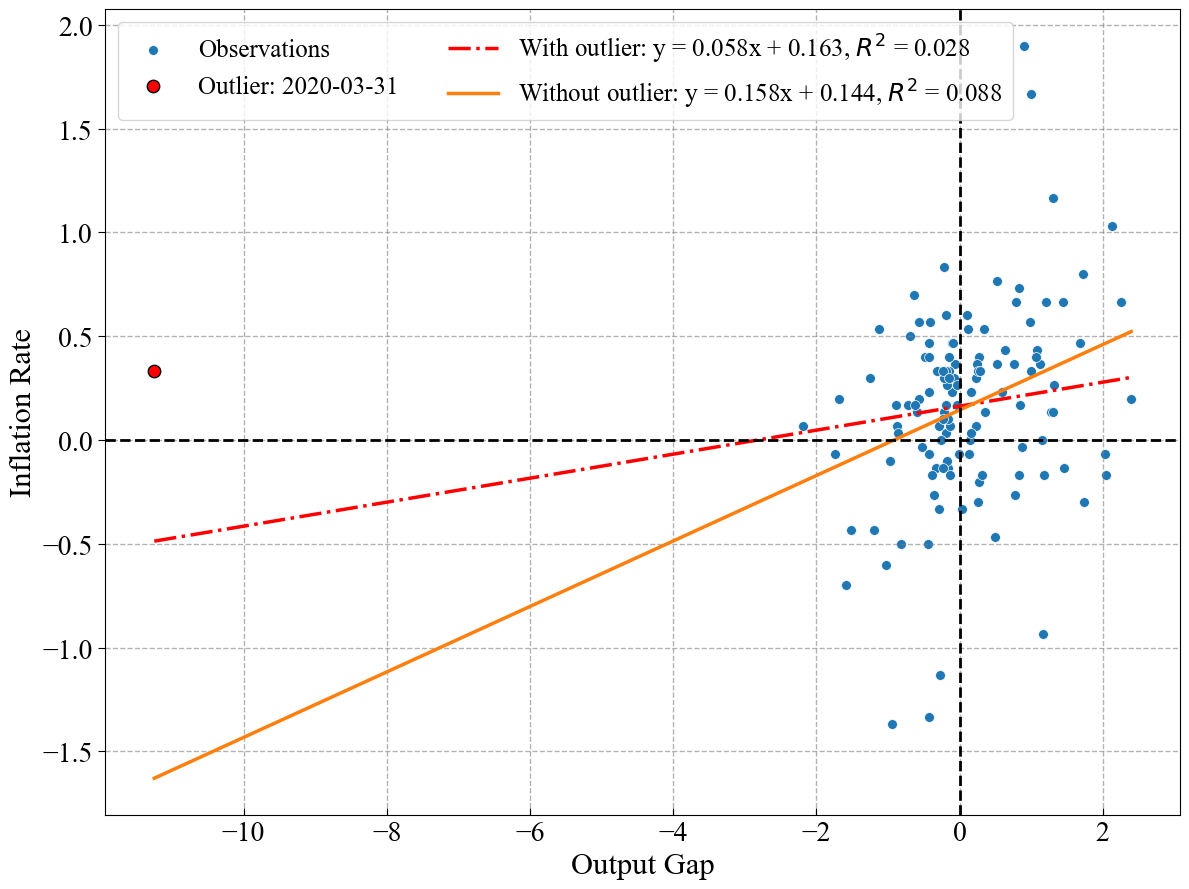

In [7]:
# 产出缺口与通货膨胀

# 1. 数据整理
data = pd.read_excel(os.path.join(path, "DATACN.xlsx"), sheet_name="MD")
data["Date"] = pd.to_datetime(data["Date"]) + pd.offsets.MonthEnd(0)
data = data.set_index("Date")

inflation = data["CPIMoM"].copy()
inflation = pd.DataFrame(inflation.groupby(inflation.index.to_period("Q")).mean())
inflation.index = inflation.index.to_timestamp(how="end").normalize()

outputgap = pd.DataFrame(hpcycle * 100)
philip = outputgap.merge(inflation, left_index=True, right_index=True, how="left")
philip.columns = ["OutputGap", "Inflation"]
philip = philip.dropna().copy()

# 2. 原始样本拟合
gap_all = philip["OutputGap"].values.copy()
inf_all = philip["Inflation"].values.copy()
coef_all = np.polyfit(gap_all, inf_all, 1)
fit_all = np.poly1d(coef_all)
xline = np.linspace(gap_all.min(), gap_all.max(), 200)
yhat_all = fit_all(xline)

# R^2（原始样本）
y_pred_all = fit_all(gap_all)
ss_res_all = np.sum((inf_all - y_pred_all) ** 2)
ss_tot_all = np.sum((inf_all - np.mean(inf_all)) ** 2)
r2_all = 1 - ss_res_all / ss_tot_all

# 3. 剔除极端值后的拟合
philip_no = philip.copy()
outlier_date = pd.Timestamp("2020-03-31")
if outlier_date in philip_no.index:
    philip_no.loc[outlier_date, ["OutputGap", "Inflation"]] = np.nan
philip_no = philip_no.dropna()
gap_no = philip_no["OutputGap"].values
inf_no = philip_no["Inflation"].values
coef_no = np.polyfit(gap_no, inf_no, 1)
fit_no = np.poly1d(coef_no)
yhat_no = fit_no(xline)

# R^2（剔除极端值后）
y_pred_no = fit_no(gap_no)
ss_res_no = np.sum((inf_no - y_pred_no) ** 2)
ss_tot_no = np.sum((inf_no - np.mean(inf_no)) ** 2)
r2_no = 1 - ss_res_no / ss_tot_no

eq_all = f"With outlier: y = {coef_all[0]:.3f}x + {coef_all[1]:.3f}, $R^2$ = {r2_all:.3f}"
eq_no = f"Without outlier: y = {coef_no[0]:.3f}x + {coef_no[1]:.3f}, $R^2$ = {r2_no:.3f}"

# 4. 绘图
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 9))
ax.scatter(philip["OutputGap"], philip["Inflation"], alpha=1, s=50, color="#1F77B4", edgecolor="white", linewidth=0.5, label="Observations")
if outlier_date in philip.index:
    ax.scatter(philip.loc[outlier_date, "OutputGap"], philip.loc[outlier_date, "Inflation"], 
               color="#FF0000", s=80, marker="o", edgecolor="black", linewidth=1, label="Outlier: 2020-03-31")
ax.plot(xline, yhat_all, color="#FF0000", linewidth=2.5, linestyle="-.", label=eq_all)
ax.plot(xline, yhat_no, color="#FF7F0E", linewidth=2.5, label=eq_no)
ax.axhline(0, color="#000000", linestyle="--", linewidth=2)
ax.axvline(0, color="#000000", linestyle="--", linewidth=2)
ax.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax.set_xlabel("Output Gap", fontsize=22)
ax.set_ylabel("Inflation Rate", fontsize=22)
ax.legend(fontsize=18, ncol=2)
plt.tight_layout()
fig.savefig("PhillipsCurve.pdf", format="pdf", bbox_inches="tight")
plt.show()

### 美国宏观经济数据分析

In [8]:
import os
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
import matplotlib.dates as mdate
plt.rcParams["font.family"] = "Times New Roman"
plt.rcParams["font.sans-serif"] = "SimHei"
plt.rcParams["xtick.direction"] = "in"
warnings.filterwarnings("ignore")

formatter = mdate.DateFormatter("%Y")   # %Y-%m -> 2023-01; %b %Y -> Jan 2023
marjorlocator = mdate.YearLocator(8)    # mdate.MonthLocator(bymonth=[1,7])

path = os.getcwd()
data = pd.read_excel(os.path.join(path, "DATAUS.xlsx"), sheet_name="MD")
data["Date"] = pd.to_datetime(data["Date"])
data = data.set_index("Date")
tcode = [5, 5, 2, 5, 5, 2, 5, 5, 2, 5]

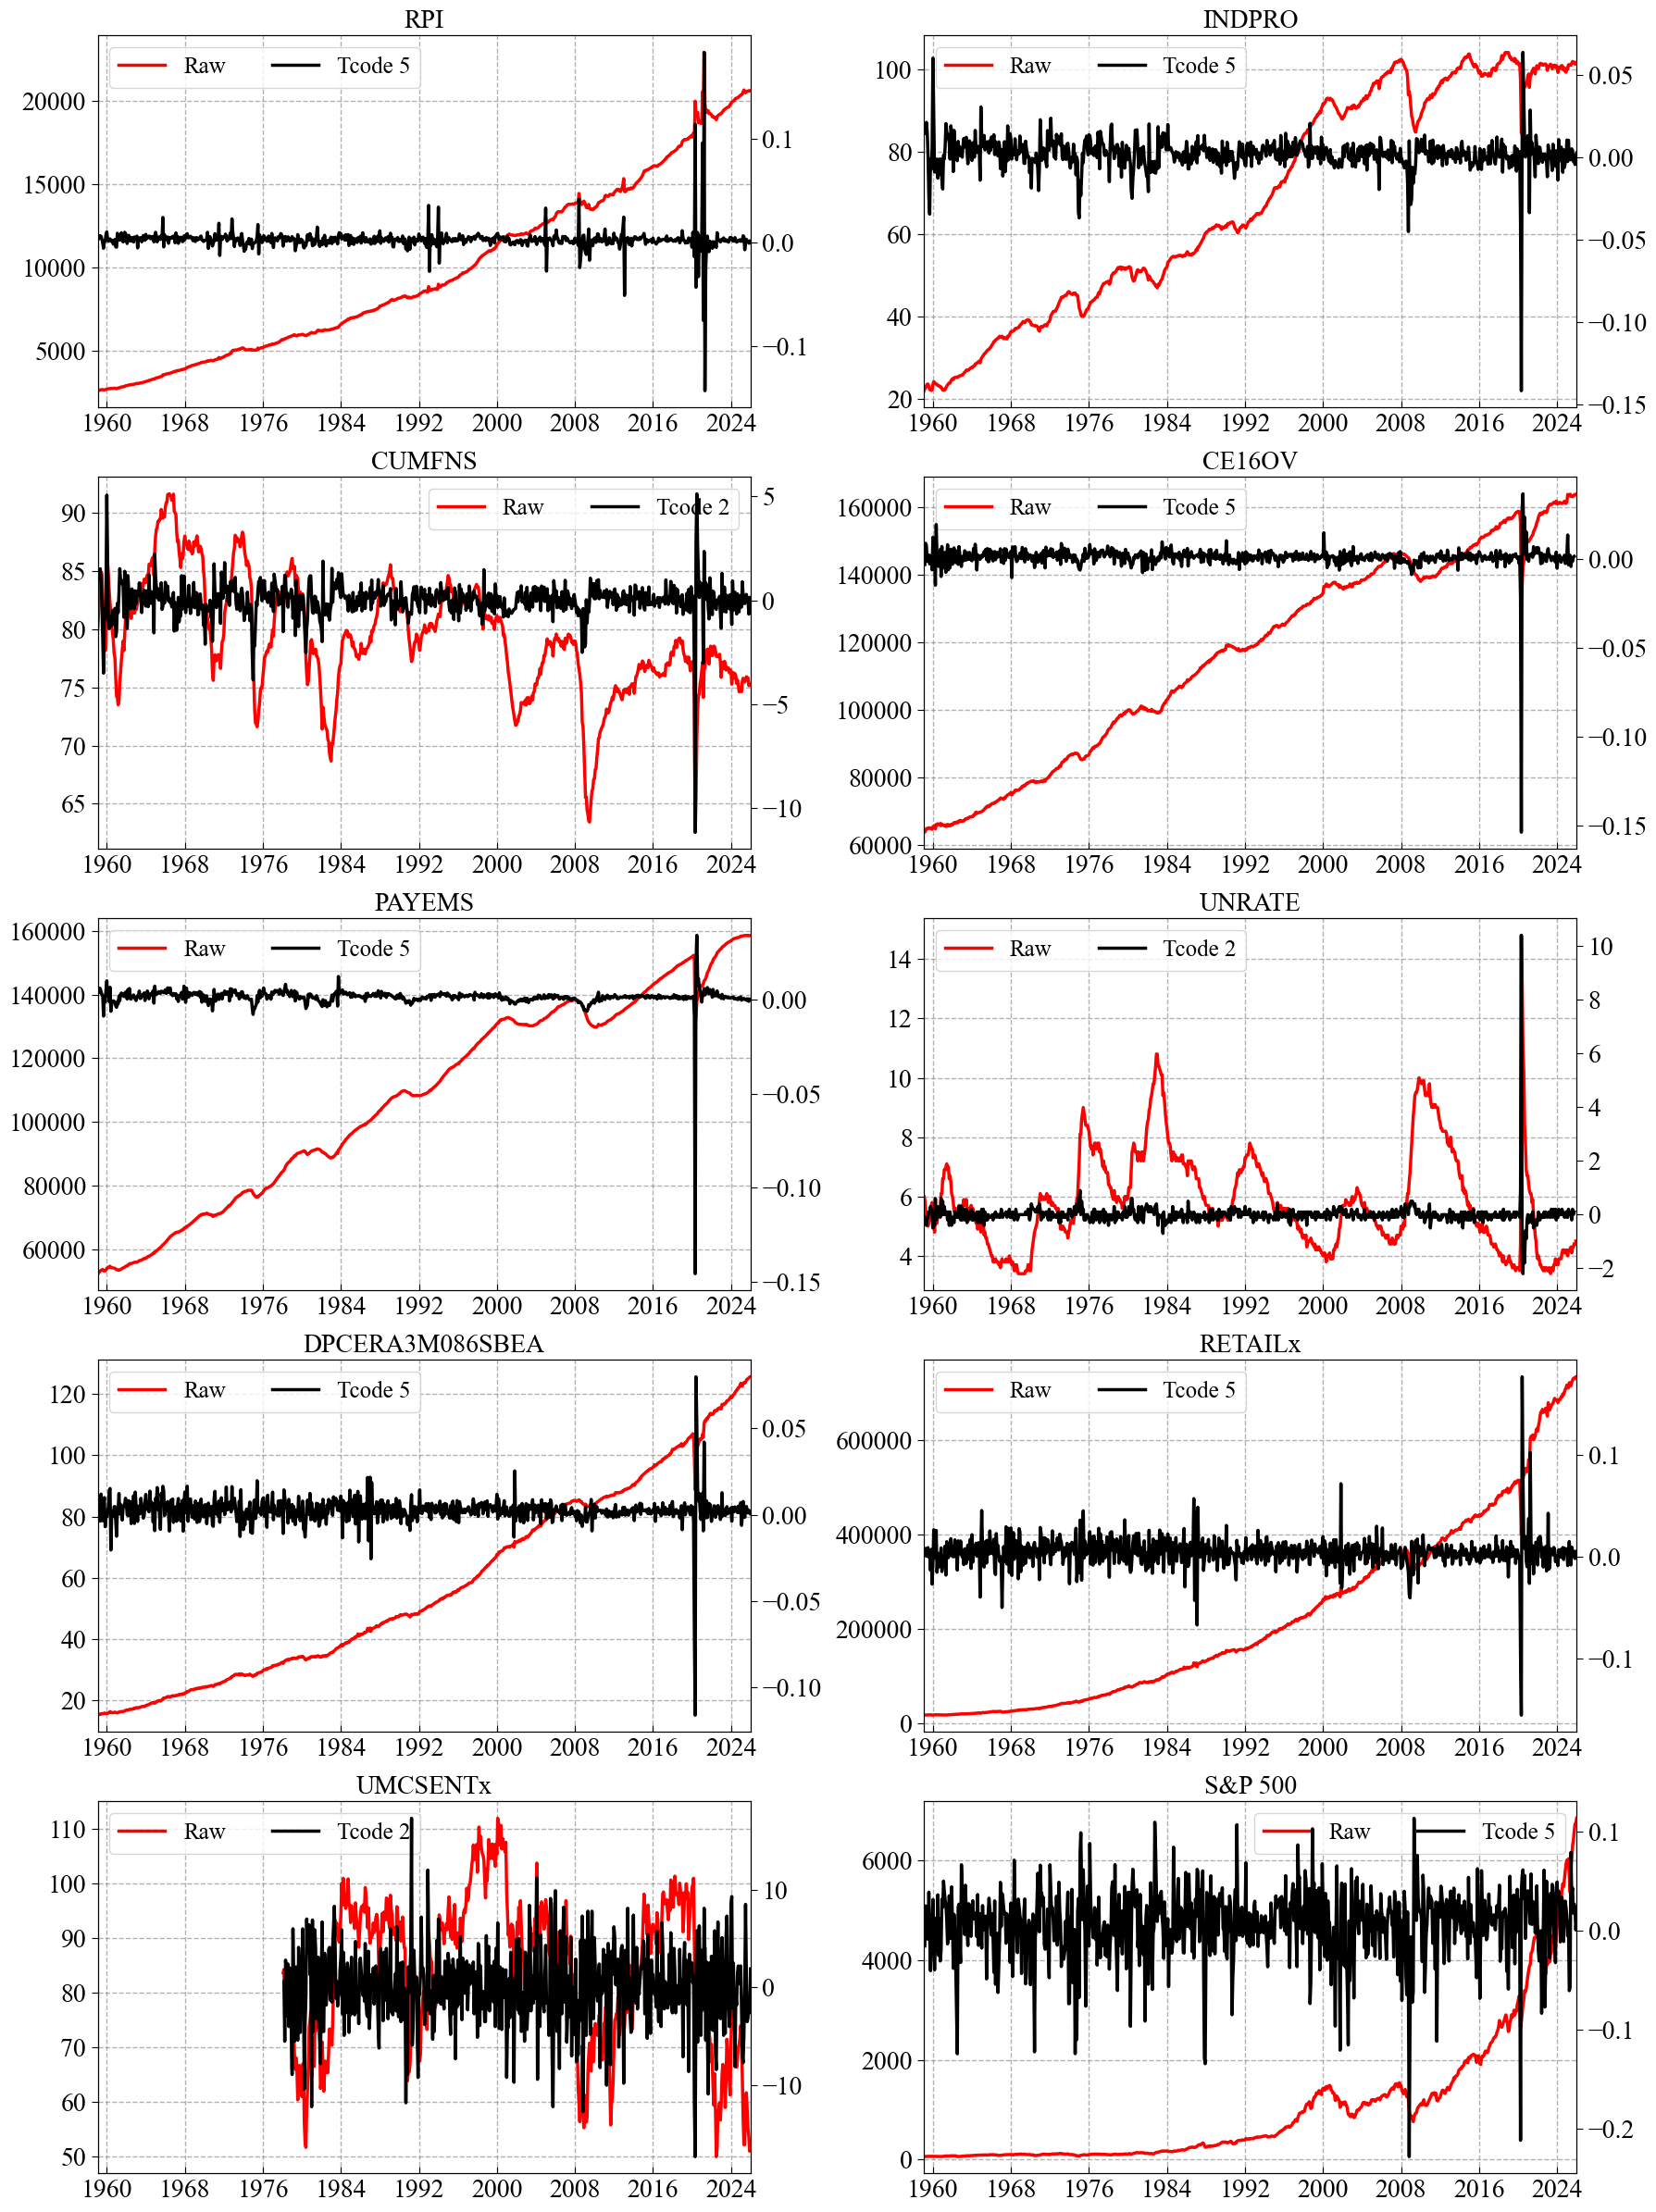

In [9]:
# Tcode 数据变换
def transxf(rawdata, tcode):
    n = rawdata.shape[0]
    small = 1e-6
    output = np.nan * np.ones(n)

    if tcode == 1:
        output = rawdata
    elif tcode == 2:
        output[1:n] = rawdata[1:n] - rawdata[0:n-1]
    elif tcode == 3:
        output[2:n] = rawdata[2:n] + rawdata[0:n-2] - 2 * rawdata[1:n-1]
    elif tcode == 4:
        if np.nanmin(rawdata) < small:
            output = np.nan
            print("We can not take log on negative values!")
        else:
            output = np.log(rawdata)
    elif tcode == 5:
        if np.nanmin(rawdata) > small:
            rawdata = np.log(rawdata)
            output[1:n] = rawdata[1:n] - rawdata[0:n-1]
    elif tcode == 6:
        if np.nanmin(rawdata) > small:
            rawdata = np.log(rawdata)
            output[2:n] = rawdata[2:n] + rawdata[0:n-2] - 2 * rawdata[1:n-1]
    elif tcode == 7:
        output1 = (rawdata[1:n] - rawdata[0:n-1])/rawdata[0:n-1]
        output[2:n] = output1[1:n-1] - output1[0:n-2]

    return output

transdata = np.nan * np.ones(data.shape)
for idx in range(data.shape[1]):
    rawdata = np.array(data.iloc[:, idx])
    cleandata = transxf(rawdata, tcode[idx])
    transdata[:, idx] = cleandata
transdata = pd.DataFrame(transdata, columns=data.columns, index=data.index)

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(18, 24))
axes = axes.flatten()
for i in range(data.shape[1]):
    col = data.columns[i]
    ax1 = axes[i]
    line1, = ax1.plot(data.index, data.iloc[:, i], color="#ff0000", alpha=1, linewidth=2.5)
    ax1.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
    ax1.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
    ax1.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
    ax1.xaxis.set_major_formatter(formatter)
    ax1.xaxis.set_major_locator(marjorlocator)
    ax1.set_xlim(data.index[0], data.index[-1])
    ax1.set_title(col, fontsize=20)
    ax2 = ax1.twinx()
    line2, = ax2.plot(transdata.index, transdata.iloc[:, i], color="#000000", alpha=1, linewidth=2.5)
    ax2.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
    ax1.legend(handles=[line1, line2], labels=["Raw", f"Tcode {tcode[i]}"], fontsize=18, ncol=2)
plt.tight_layout()
plt.savefig("FREDTransform.pdf", dpi=400, bbox_inches="tight")
plt.show()

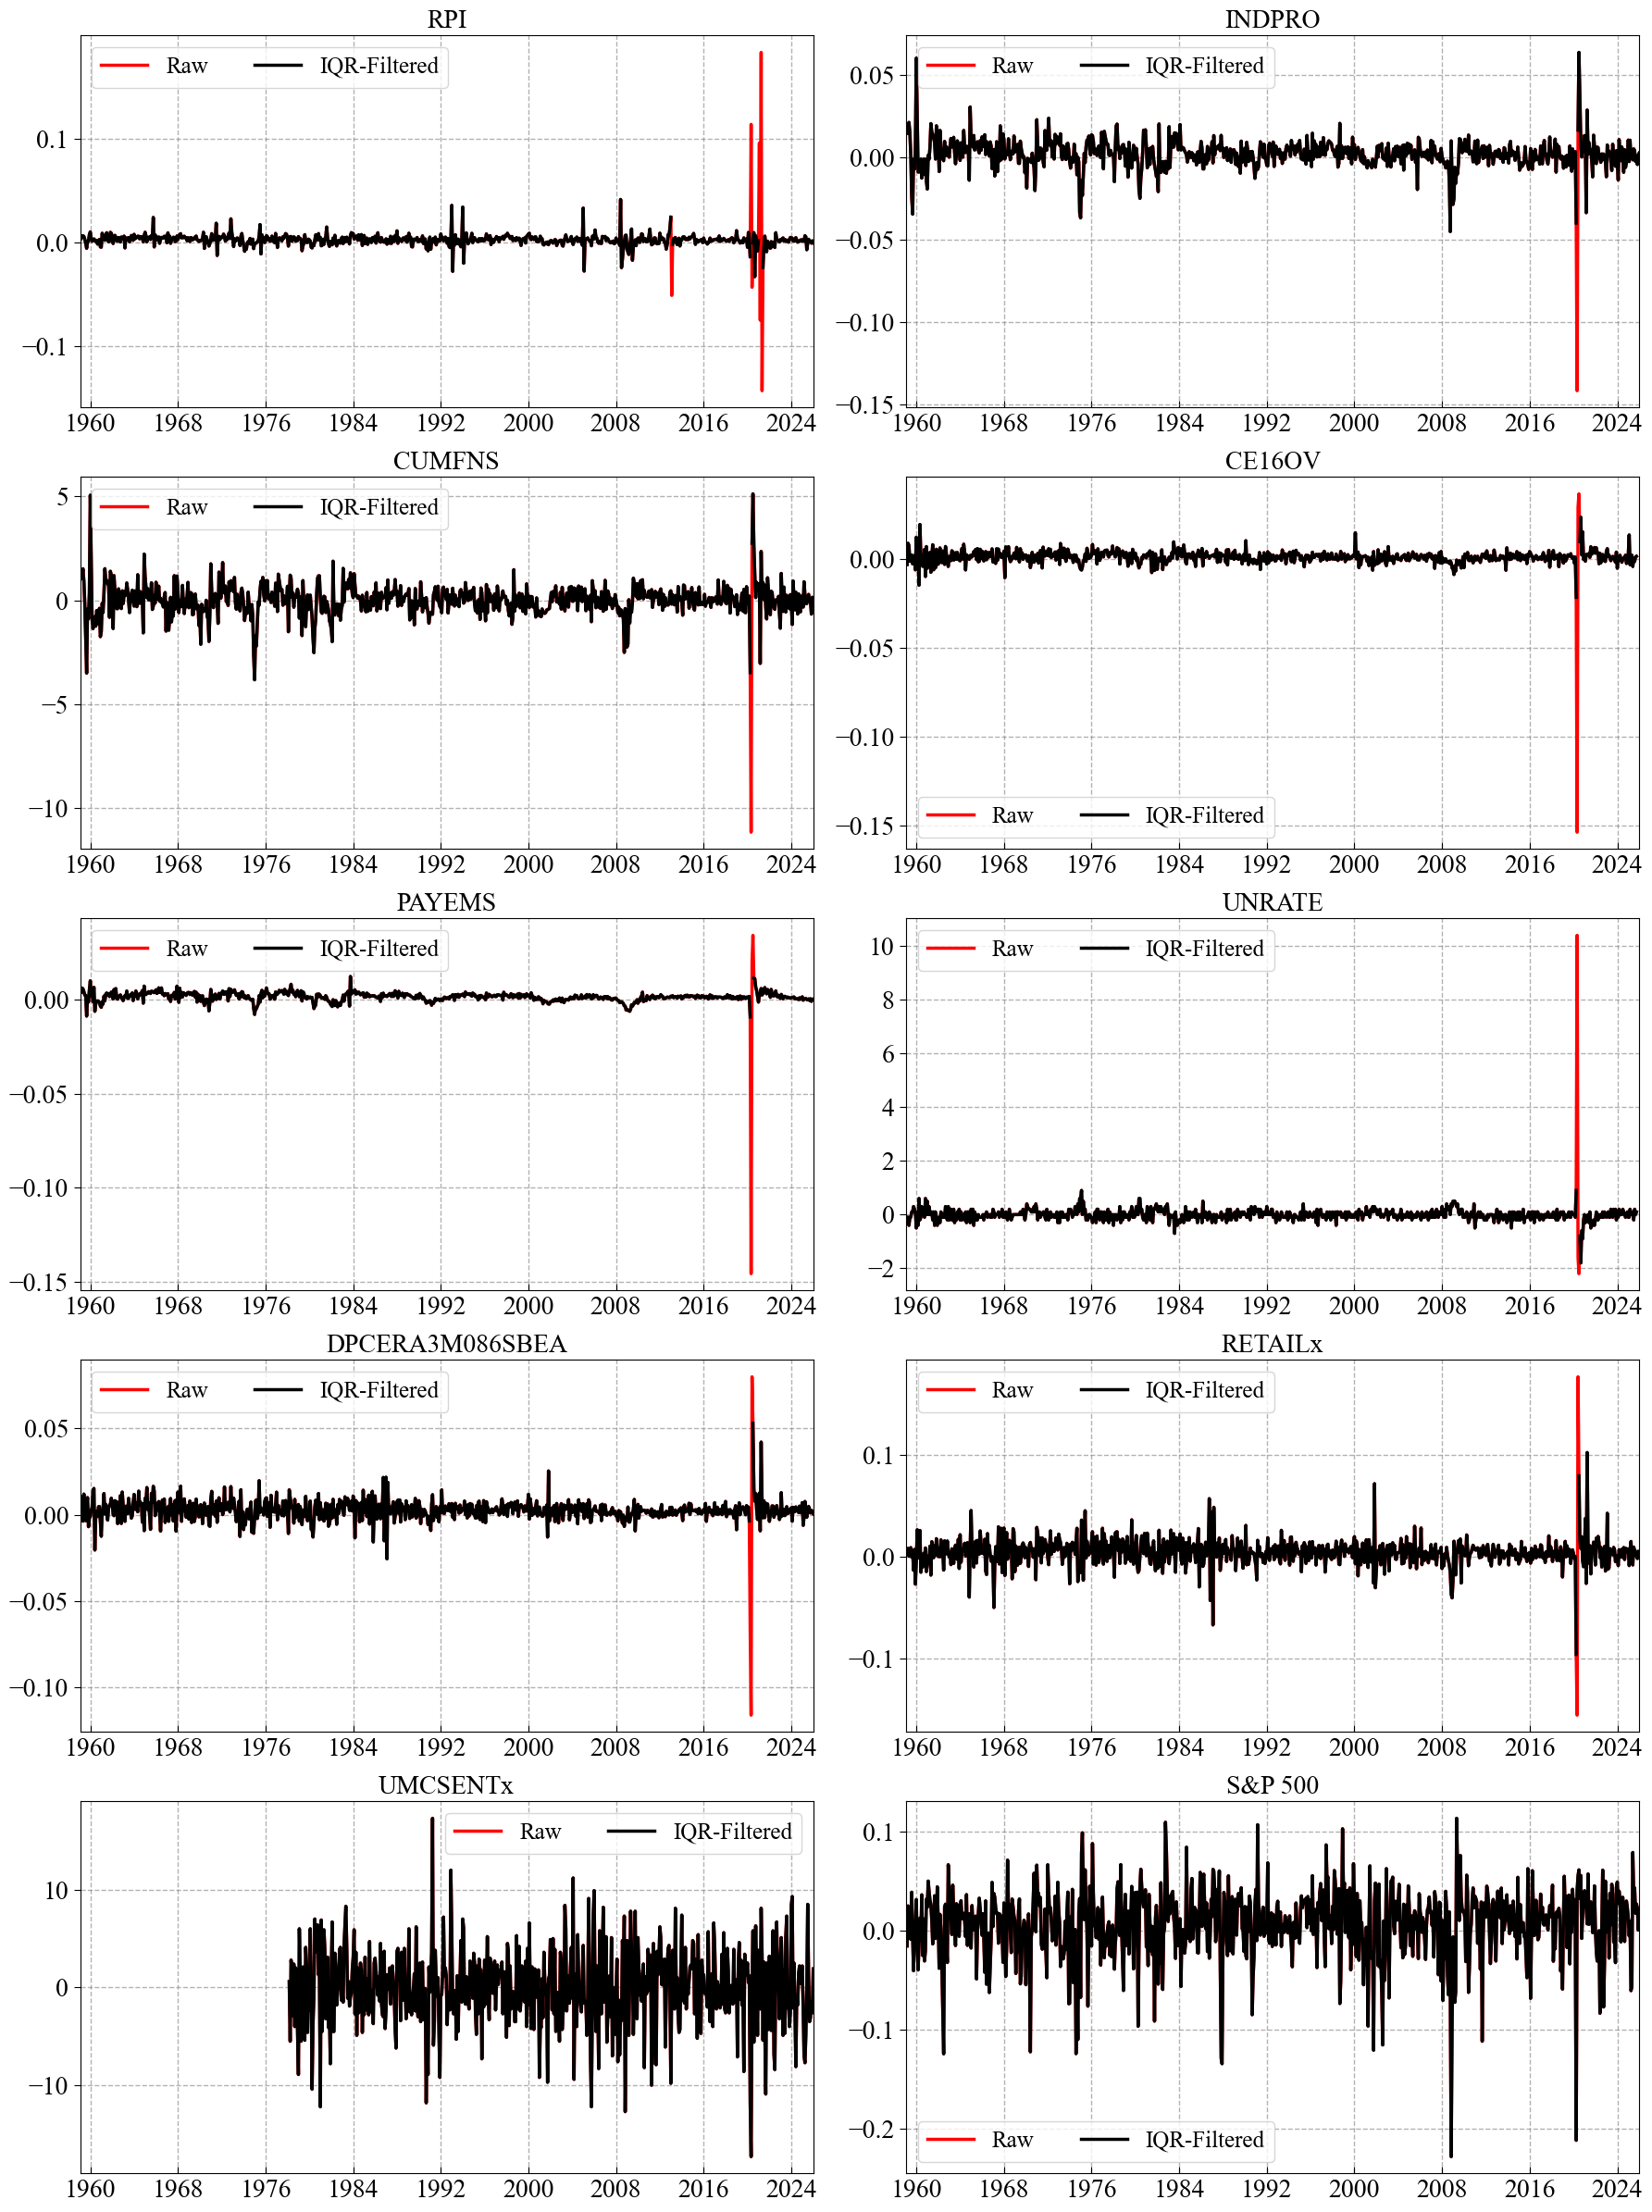

In [10]:
# 剔除极端异常值
def remove_outlier_median_iqr_df(df, k=10):
    df_clean = df.copy()
    outlier_info = {}

    for col in df.columns:
        med = df[col].median()
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1
        lower_bound = med - k * IQR
        upper_bound = med + k * IQR
        mask = (df[col] < lower_bound) | (df[col] > upper_bound)
        df_clean.loc[mask, col] = np.nan
        outlier_info[col] = mask.sum()

    return df_clean, outlier_info

noOutlierdata, outlier_info = remove_outlier_median_iqr_df(transdata, k=10)

fig, axes = plt.subplots(nrows=5, ncols=2, figsize=(18, 24))
axes = axes.flatten()
for i in range(data.shape[1]):
    col = data.columns[i]
    ax1 = axes[i]
    line1, = ax1.plot(transdata.index, transdata.iloc[:, i], color="#ff0000", alpha=1, linewidth=2.5)
    ax1.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
    ax1.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
    ax1.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
    ax1.xaxis.set_major_formatter(formatter)
    ax1.xaxis.set_major_locator(marjorlocator)
    ax1.set_xlim(data.index[0], data.index[-1])
    ax1.set_title(col, fontsize=20)
    ax1.plot(noOutlierdata.index, noOutlierdata.iloc[:, i], color="#000000", alpha=1, linewidth=2.5)
    ax1.legend(handles=[line1, line2], labels=["Raw", "IQR-Filtered"], fontsize=18, ncol=2)
plt.tight_layout()
plt.savefig("OutliersRemoved.pdf", dpi=400, bbox_inches="tight")
plt.show()

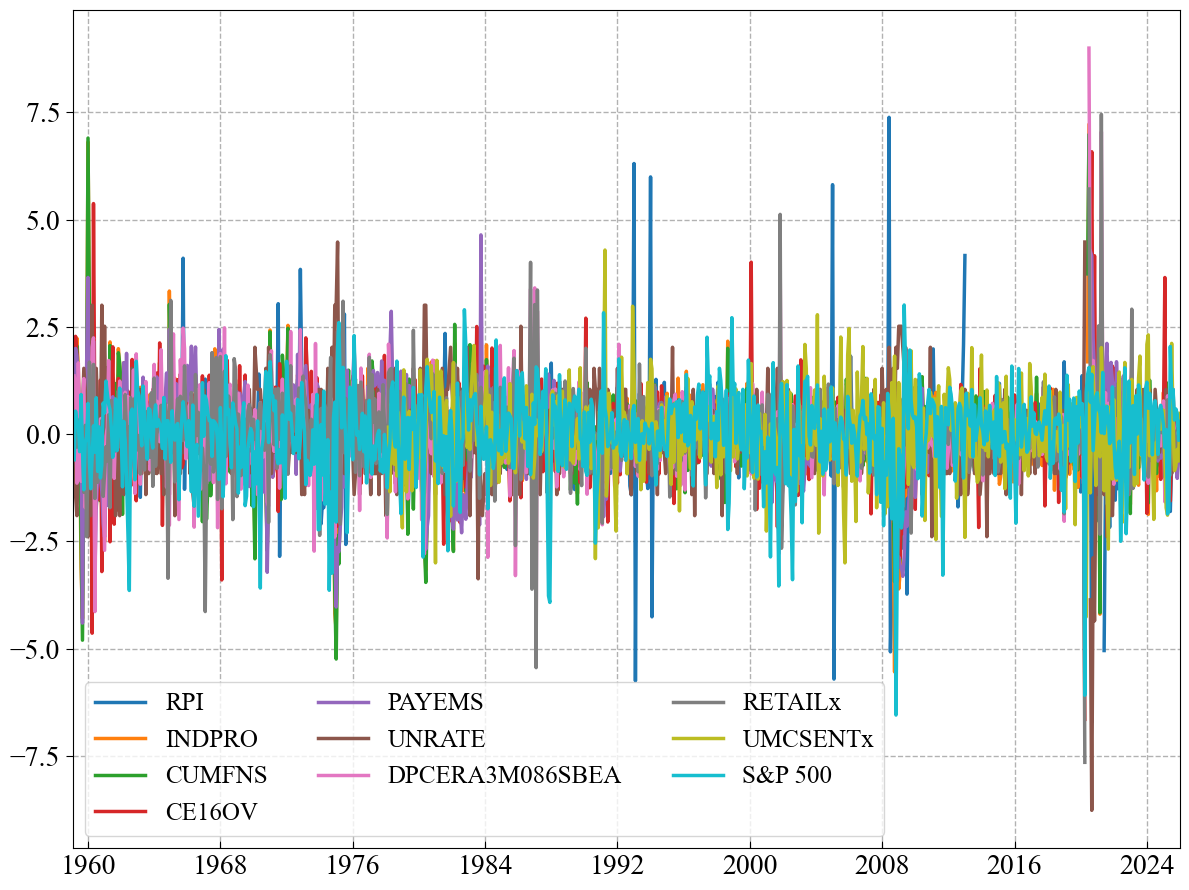

In [11]:
# 数据标准化
zscore = (noOutlierdata - noOutlierdata.mean()) / noOutlierdata.std()
zscore = zscore.asfreq("ME")

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 9))
for i in range(data.shape[1]):
    col = data.columns[i]
    ax.plot(zscore.index, zscore.iloc[:, i], alpha=1, linewidth=2.5, label=col)
    ax.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
    ax.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
    ax.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
    ax.xaxis.set_major_formatter(formatter)
    ax.xaxis.set_major_locator(marjorlocator)
    ax.set_xlim(data.index[0], data.index[-1])
ax.legend(fontsize=18, ncol=3)
plt.tight_layout()
plt.savefig("ZScore.pdf", dpi=400, bbox_inches="tight")
plt.show()

In [12]:
# 动态因子模型估计
mod = sm.tsa.DynamicFactor(zscore, k_factors=1, factor_order=2, error_order=1)
init_res = mod.fit(method="powell", disp=False)
res = mod.fit(init_res.params, disp=False)
common_factor = pd.Series((-1)*np.asarray(res.factors.filtered)[0], index=transdata.index, name="commonfactor")
print(res.summary())

                                                                         Statespace Model Results                                                                         
Dep. Variable:     ['RPI', 'INDPRO', 'CUMFNS', 'CE16OV', 'PAYEMS', 'UNRATE', 'DPCERA3M086SBEA', 'RETAILx', 'UMCSENTx', 'S&P 500']   No. Observations:                  804
Model:                                                                                          DynamicFactor(factors=1, order=2)   Log Likelihood               -9507.876
                                                                                                                   + AR(1) errors   AIC                          19079.751
Date:                                                                                                            Sat, 21 Mar 2026   BIC                          19229.818
Time:                                                                                                                    00:01:49   HQIC         

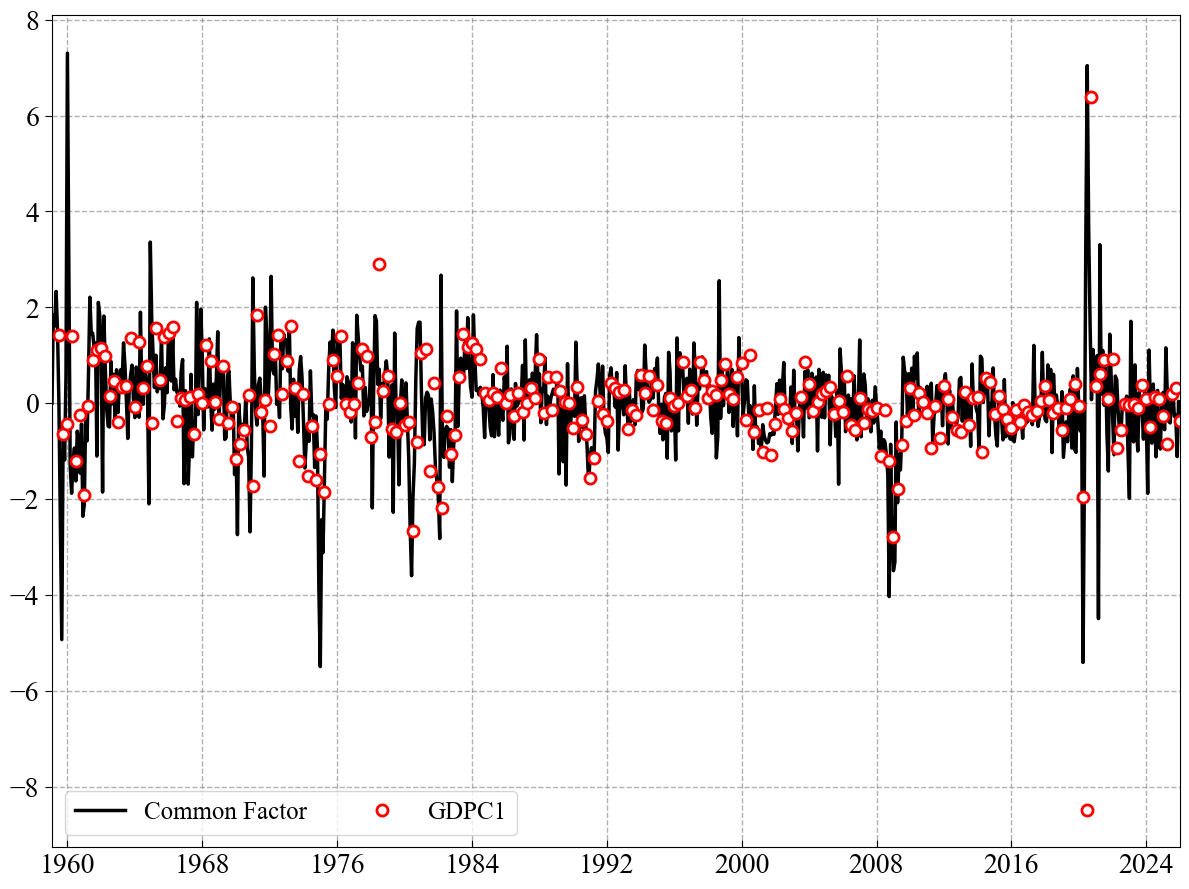

In [13]:
# 动态因子与季度经济增速展示
data = pd.read_excel(os.path.join(path, "DATAUS.xlsx"), sheet_name="QD")
data["Date"] = pd.to_datetime(data["Date"])
data = data.set_index("Date")
gdpgrowth = np.log(data).diff()
zscoregdp = (gdpgrowth - gdpgrowth.mean())/gdpgrowth.std()

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(12, 9))
ax.plot(common_factor.index, common_factor, alpha=1, color="#000000", linewidth=2.5, label="Common Factor")
ax.plot(zscoregdp.index, zscoregdp, alpha=1, linestyle="", label="GDPC1",
        marker="o", markersize=8, markerfacecolor="#FFFFFF", markeredgewidth=2, markeredgecolor="#FF0000")
ax.tick_params(axis="y", which="both", length=5, labelsize=20, pad=4)
ax.grid(axis="both", linestyle="--", color="#808080", alpha=0.6, linewidth=1)
ax.tick_params(axis="x", which="both", length=5, labelsize=20, pad=4)
ax.xaxis.set_major_formatter(formatter)
ax.xaxis.set_major_locator(marjorlocator)
ax.set_xlim(common_factor.index[0], common_factor.index[-1])
ax.legend(fontsize=18, ncol=3)
plt.tight_layout()
plt.savefig("DynamicFactor.pdf", dpi=400, bbox_inches="tight")
plt.show()